In [8]:


# Add the NumCompute project directory to Python's import path.
import sys
from pathlib import Path

project_root = Path.cwd()

if not (project_root / "numcompute_stream").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

print("Project directory:", project_root)



# Assignment 2.2: Streaming Classification Demo
# Import our completed streaming components.

import numpy as np
import matplotlib.pyplot as plt

from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.ensemble import EnsembleClassifier
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.csv_stream import read_csv_chunks
from numcompute_stream.visualise import (
    plot_accuracy,
    plot_memory_usage,
    plot_model_comparison,
)

print("NumCompute streaming components loaded successfully!")


Project directory: c:\Users\Benarjee\Documents\Programming _2.2_\PfAI_Assignment_2.2\NumCompute
NumCompute streaming components loaded successfully!


In [9]:

# Generate a reproducible CSV classification dataset.
from demo.stream_demo import create_sample_csv

from pathlib import Path

csv_path = Path("stream_sample.csv")
create_sample_csv(csv_path, n_samples=200)

print("CSV dataset created:", csv_path)
print("Total samples: 200")


CSV dataset created: stream_sample.csv
Total samples: 200


In [10]:

# Step 31C: Train and evaluate the streaming decision tree.

model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

trainer = StreamTrainer(model)

chunk_results = []

for X_chunk, y_chunk in read_csv_chunks(
    csv_path, chunk_size=20
):
    # Evaluate before training on the new chunk.
    if trainer.is_fitted:
        accuracy = trainer.score_chunk(X_chunk, y_chunk)
        chunk_results.append(accuracy)

        print(
            f"Chunk {trainer.chunk_count + 1}: "
            f"Accuracy = {accuracy:.2%}"
        )

    # Update the model using the incoming chunk.
    trainer.fit_chunk(X_chunk, y_chunk)

print("\nStreaming training completed!")
print("Total chunks:", trainer.chunk_count)
print("Evaluation chunks:", len(chunk_results))


Chunk 2: Accuracy = 70.00%
Chunk 3: Accuracy = 80.00%
Chunk 4: Accuracy = 95.00%
Chunk 5: Accuracy = 95.00%
Chunk 6: Accuracy = 100.00%
Chunk 7: Accuracy = 85.00%
Chunk 8: Accuracy = 95.00%
Chunk 9: Accuracy = 85.00%
Chunk 10: Accuracy = 95.00%

Streaming training completed!
Total chunks: 10
Evaluation chunks: 9


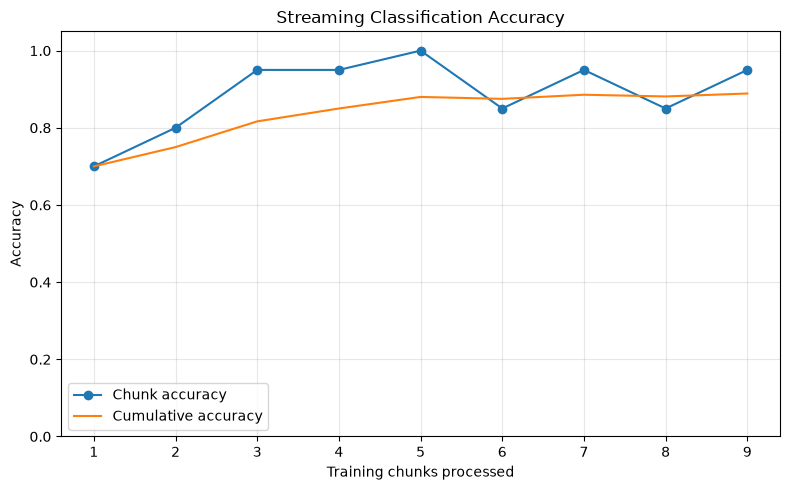

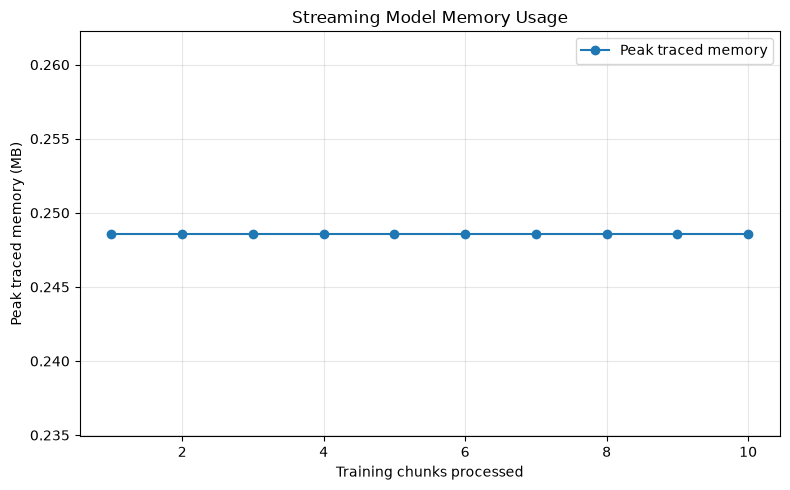

Accuracy and memory graphs generated successfully!


In [11]:

# Visualise model accuracy and memory usage across chunks.

accuracy_fig, accuracy_ax = plot_accuracy(trainer.get_history())
plt.show()

memory_fig, memory_ax = plot_memory_usage(trainer.get_history())
plt.show()

print("Accuracy and memory graphs generated successfully!")


In [ ]:

# Compare single-tree and ensemble accuracy on identical CSV chunks.

tree_trainer = StreamTrainer(
    DecisionTreeClassifier(max_depth=5, random_state=42)
)

ensemble_trainer = StreamTrainer(
    EnsembleClassifier(
        n_estimators=5,
        max_depth=5,
        max_features="sqrt",
        random_state=42
    )
)

for X_chunk, y_chunk in read_csv_chunks(csv_path, chunk_size=20):
    for current_trainer in (tree_trainer, ensemble_trainer):
        if current_trainer.is_fitted:
            current_trainer.score_chunk(X_chunk, y_chunk)

        current_trainer.fit_chunk(X_chunk, y_chunk)

comparison_fig, comparison_ax = plot_model_comparison(
    tree_trainer.get_history(),
    ensemble_trainer.get_history()
)

plt.show()

print("Single Tree vs Ensemble comparison generated!")
